# Evaluación Formativa 2: Práctica de Modelamiento Predictivo

**Curso:** MCDI501 - Estadística Computacional para la Toma de Decisiones
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello

| Campo | Información |
|-------|-------------|
| **Grupo** | 4 |
| **Integrante 1** | Jeremmy Díaz Alfaro |
| **Integrante 2** | Karim Zaid Sánchez |
| **Integrante 3** | Laura Arenas Kosin |
| **Dataset** | Rain in Australia (weatherAUS, Kaggle) |

En esta formativa ajustamos **un** modelo de regresión logística para predecir si mañana llueve (`RainTomorrow`), usando una estrategia simple de datos faltantes (mediana). Es la práctica antes de la Sumativa 3, donde se harán tres modelos, imputación por regresión y bootstrap de los coeficientes.

Semilla fija: `42`.

## Configuración del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, roc_curve, auc)

# carpeta del proyecto, para importar src y guardar figuras
raiz = Path.cwd().resolve()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.append(str(raiz))
from src.carga_datos import cargar_weather

SEED = 42
np.random.seed(SEED)
FIGURAS = raiz / "figuras"
FIGURAS.mkdir(exist_ok=True)

# misma paleta de la Formativa 1
INK = '#2b2b2b'; TEAL = '#2e6b75'; OCHRE = '#c4862f'; TERRA = '#a35140'
BG = '#f6f1ea'; GRID = '#ddd5c6'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.family': 'serif', 'font.size': 10,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

---
# PARTE 1: Preparación de datos para el modelamiento
## 1.1 Carga y referencia a los hallazgos anteriores

In [2]:
df = cargar_weather()
TARGET = 'RainTomorrow'
print(f"Dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas")
df.head()

Dataset: 145,460 filas × 23 columnas


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Lo que encontramos en la Formativa 1 (análisis exploratorio)

- **Objetivo:** `RainTomorrow` (Yes/No). Está desbalanceado: en el 22,4 % de los días llueve al día siguiente. Hay 3.267 registros sin dato en el objetivo.
- **Faltantes:** 21 de 23 variables tienen faltantes. Las peores son `Sunshine` (48 %), `Evaporation` (43 %), `Cloud3pm` (41 %) y `Cloud9am` (38 %). En `Sunshine` el faltante no es al azar: 19 de 49 ciudades nunca la miden.
- **Valores raros:** 3 registros con nubosidad 9 (las octas van de 0 a 8). La lluvia diaria tiene una cola muy larga (mediana 0, máximo 371 mm).
- **Sin duplicados.**

Abajo calculamos de nuevo la correlación de cada variable numérica con el objetivo, para tenerla a mano.

In [3]:
y_num = df[TARGET].map({'No': 0, 'Yes': 1})
numericas = df.select_dtypes(include='number').columns
corr_target = df[numericas].corrwith(y_num).sort_values()
faltante = df[numericas].isna().mean() * 100
resumen = pd.DataFrame({'r con RainTomorrow': corr_target, '% faltante': faltante}).round(2)
resumen.sort_values('r con RainTomorrow', key=abs, ascending=False)

,r con RainTomorrow,% faltante
Humidity3pm,0.45,3.10
Sunshine,-0.45,48.01
Cloud3pm,0.38,40.81
Cloud9am,0.32,38.42
Humidity9am,0.26,1.82
Pressure9am,-0.25,10.36
Rainfall,0.24,2.24
Pressure3pm,-0.23,10.33
WindGustSpeed,0.23,7.06
Temp3pm,-0.19,2.48


### Validación de las correlaciones con bootstrap

Para no elegir variables solo por una correlación puntual, revisamos si es **estable**: recalculamos la correlación en 500 remuestras bootstrap y armamos un intervalo de confianza del 95 %. Si el intervalo no incluye el 0, la consideramos estable. Lo hacemos para las candidatas con más relación con el objetivo.

In [4]:
candidatas = ['Humidity3pm', 'Sunshine', 'Cloud3pm', 'Pressure3pm', 'Rainfall',
              'WindGustSpeed', 'Temp3pm']
base = df[candidatas].assign(y=y_num).dropna(subset=['y'])

rng = np.random.default_rng(SEED)
B = 500
filas = []
for v in candidatas:
    par = base[[v, 'y']].dropna().to_numpy()
    n = len(par)
    rs = []
    for _ in range(B):
        m = par[rng.integers(0, n, n)]
        rs.append(np.corrcoef(m[:, 0], m[:, 1])[0, 1])
    lo, hi = np.percentile(rs, [2.5, 97.5])
    filas.append({'Variable': v, 'r': np.corrcoef(par[:, 0], par[:, 1])[0, 1],
                  'IC95 inf': lo, 'IC95 sup': hi, 'Estable': not (lo <= 0 <= hi),
                  '% faltante': base[v].isna().mean() * 100})
tabla_boot = pd.DataFrame(filas).set_index('Variable').round(3)
tabla_boot

,r,IC95 inf,IC95 sup,Estable,% faltante
Variable,,,,,
Humidity3pm,0.446,0.442,0.450,True,2.539
Sunshine,-0.451,-0.457,-0.444,True,47.693
Cloud3pm,0.382,0.377,0.387,True,40.152
Pressure3pm,-0.226,-0.232,-0.221,True,9.832
Rainfall,0.239,0.232,0.247,True,0.989
WindGustSpeed,0.234,0.228,0.240,True,6.519
Temp3pm,-0.192,-0.197,-0.188,True,1.917


Todas las candidatas tienen intervalos estrechos que no tocan el 0, porque la muestra es muy grande. Así que, además de la estabilidad, para elegir las variables miramos el **porcentaje de faltantes** (ver 2.1).

---
## 1.2 Tratamiento básico de datos

In [5]:
# 1) Sacamos las filas sin dato en el objetivo: no se puede entrenar ni evaluar sin saber la respuesta
datos = df.dropna(subset=[TARGET]).copy()
datos['y'] = (datos[TARGET] == 'Yes').astype(int)

# 2) Nubosidad 9 no es válida (octas 0 a 8): la dejamos como faltante
for c in ['Cloud9am', 'Cloud3pm']:
    datos.loc[datos[c] == 9, c] = np.nan

print(f"Filas para modelar: {len(datos):,}")
print(f"Proporción de días con lluvia mañana: {datos['y'].mean():.3f}")

Filas para modelar: 142,193
Proporción de días con lluvia mañana: 0.224


### Variables del modelo y partición train/test

Elegimos 4 predictores (la justificación está en la Parte 2.1). Separamos 70 % para entrenar y 30 % para probar, **estratificando** por el objetivo para que los dos grupos tengan la misma proporción de días con lluvia.

In [6]:
predictores = ['Humidity3pm', 'Pressure3pm', 'WindGustSpeed', 'Rainfall']

X = datos[predictores]
y = datos['y']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")
print(f"% lluvia en train: {y_train.mean()*100:.1f}%   en test: {y_test.mean()*100:.1f}%")
print("\nFaltantes en train antes de imputar:")
print(X_train.isna().sum())

Train: 99,535   Test: 42,658
% lluvia en train: 22.4%   en test: 22.4%

Faltantes en train antes de imputar:
Humidity3pm      2536
Pressure3pm      9809
WindGustSpeed    6476
Rainfall          966
dtype: int64


### Faltantes: imputación por mediana

Usamos la **mediana** porque es simple y no se deja arrastrar por valores extremos (la lluvia tiene una cola muy larga). La mediana se calcula **solo con train** y se aplica a train y test, así el conjunto de prueba no "filtra" información al entrenamiento.

También recortamos la lluvia al percentil 99 de train, para que los pocos días extremos no dominen el modelo.

In [7]:
medianas = X_train.median()
X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)

tope_lluvia = X_train['Rainfall'].quantile(0.99)
X_train['Rainfall'] = X_train['Rainfall'].clip(upper=tope_lluvia)
X_test['Rainfall'] = X_test['Rainfall'].clip(upper=tope_lluvia)

print("Medianas usadas:"); print(medianas.round(1))
print(f"\nTope de lluvia (P99 de train): {tope_lluvia:.1f} mm")
print(f"Faltantes restantes: train={X_train.isna().sum().sum()}, test={X_test.isna().sum().sum()}")
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

Medianas usadas:
Humidity3pm        52.0
Pressure3pm      1015.2
WindGustSpeed      39.0
Rainfall            0.0
dtype: float64

Tope de lluvia (P99 de train): 37.0 mm
Faltantes restantes: train=0, test=0


### Estandarización

Pasamos cada predictor a media 0 y desviación 1 (con los parámetros de train). Así los odds ratios se leen "por cada desviación estándar" y se pueden comparar entre variables que tienen unidades distintas (%, hPa, km/h, mm).

In [8]:
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=predictores, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=predictores, index=X_test.index)
X_train_sc.describe().round(2).loc[['mean', 'std']]

,Humidity3pm,Pressure3pm,WindGustSpeed,Rainfall
mean,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


### Figura 1 - Distribución de dos predictores por clase

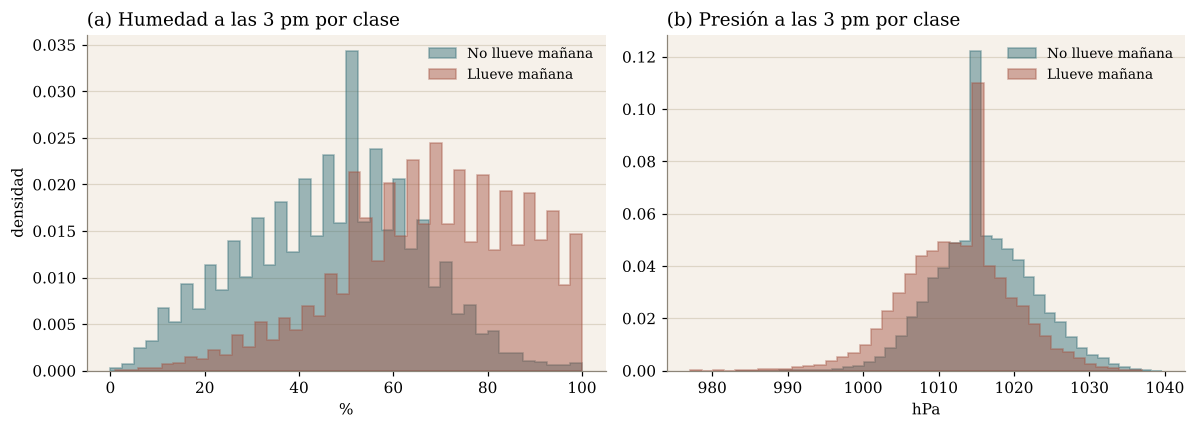

In [9]:
tr = X_train.assign(y=y_train)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for clase, color, label in [(0, TEAL, 'No llueve mañana'), (1, TERRA, 'Llueve mañana')]:
    sub = tr[tr['y'] == clase]
    ax[0].hist(sub['Humidity3pm'], bins=40, density=True, histtype='stepfilled',
               alpha=0.45, color=color, edgecolor=color, label=label)
    ax[1].hist(sub['Pressure3pm'], bins=40, density=True, histtype='stepfilled',
               alpha=0.45, color=color, edgecolor=color, label=label)
ax[0].set_title('(a) Humedad a las 3 pm por clase'); ax[0].set_xlabel('%'); ax[0].set_ylabel('densidad')
ax[1].set_title('(b) Presión a las 3 pm por clase'); ax[1].set_xlabel('hPa')
for a in ax:
    a.legend(fontsize=9, frameon=False); a.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_dist.png', bbox_inches='tight')
plt.show()

**Lectura.** Los días previos a lluvia tienen la humedad de la tarde claramente más alta, por eso esperamos que sea el predictor más fuerte. Con la presión pasa lo contrario: antes de un día con lluvia la presión tiende a ser más baja, aunque las dos curvas se traslapan bastante más.

Los picos altos en 52 % de humedad y en 1015 hPa de presión no son reales: son los faltantes que rellenamos con la mediana (en la presión es casi el 10 % de los datos). Es justamente la limitación de imputar con la mediana: amontona valores en un solo punto y reduce la variabilidad. En la S3 se reemplaza por imputación por regresión.

---
# PARTE 2: Modelo de regresión logística
## 2.1 Selección de variables

| Variable | r con objetivo | IC bootstrap 95 % | % faltante | Por qué la incluimos |
|---|---|---|---|---|
| Humedad 3 pm | +0,45 | estable | 2,5 % | La más relacionada con la lluvia de mañana; aire húmedo en la tarde |
| Presión 3 pm | −0,23 | estable | 9,8 % | Presión baja suele venir con mal tiempo |
| Ráfaga de viento | +0,23 | estable | 6,5 % | Los frentes de lluvia traen viento fuerte; casi no se relaciona con la humedad |
| Lluvia de hoy (mm) | +0,24 | estable | 1,0 % | Si hoy llovió, mañana es más probable que llueva (46 % vs 15 % en la F1) |

**Las que dejamos fuera y por qué:**
- `Sunshine` (r = −0,45) y `Cloud3pm` (r = +0,38) son muy buenas señales, pero les falta el 48 % y el 40 % de los datos. Rellenar casi la mitad con la mediana inventaría información, y en `Sunshine` el faltante depende de la ciudad. Las dejamos para la S3, con imputación por regresión.
- `Temp3pm` (r = −0,19) está bastante correlacionada con la humedad (r = −0,56), así que aportaría información repetida.
- `RainToday` es casi lo mismo que `Rainfall` (RainToday = Yes cuando llueve más de 1 mm), así que usamos solo una.

## 2.2 Ajuste del modelo

In [10]:
X_train_sm = sm.add_constant(X_train_sc)
modelo = sm.Logit(y_train, X_train_sm).fit(disp=0)
print(modelo.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                99535
Model:                          Logit   Df Residuals:                    99530
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.2828
Time:                        21:51:56   Log-Likelihood:                -37988.
converged:                       True   LL-Null:                       -52968.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -1.7382      0.011   -159.471      0.000      -1.760      -1.717
Humidity3pm       1.3225      0.011    115.142      0.000       1.300       1.345
Pressure3pm      -0.4655      0.010    -

### Odds ratios

In [11]:
ic = np.exp(modelo.conf_int())
tabla_or = pd.DataFrame({
    'Coeficiente': modelo.params,
    'Odds ratio': np.exp(modelo.params),
    'IC95 OR inf': ic[0],
    'IC95 OR sup': ic[1],
    'p-valor': modelo.pvalues,
    'Significativo (α=0,05)': modelo.pvalues < 0.05,
}).round(4)
tabla_or

,Coeficiente,Odds ratio,IC95 OR inf,IC95 OR sup,p-valor,"Significativo (α=0,05)"
const,-1.7382,0.1758,0.1721,0.1796,0.0,True
Humidity3pm,1.3225,3.7530,3.6694,3.8384,0.0,True
Pressure3pm,-0.4655,0.6278,0.6157,0.6403,0.0,True
WindGustSpeed,0.4590,1.5825,1.5532,1.6123,0.0,True
Rainfall,0.2129,1.2373,1.2172,1.2577,0.0,True


### Interpretación

Como las variables están estandarizadas, cada odds ratio (OR) dice cuánto se multiplican las *odds* de que llueva mañana cuando la variable sube una desviación estándar, dejando las demás fijas.

- **Humedad 3 pm (OR ≈ 3,8):** es el factor más fuerte. Una desviación estándar más de humedad (unos 20 puntos de %) multiplica las odds de lluvia por casi 4.
- **Presión 3 pm (OR ≈ 0,63):** a mayor presión, menos lluvia. Una desviación estándar más (unos 7 hPa) baja las odds en alrededor de 37 %.
- **Ráfaga de viento (OR ≈ 1,6):** con viento más fuerte suben las odds de lluvia.
- **Lluvia de hoy (OR ≈ 1,24):** aporta, pero menos de lo que se esperaba. Parte de su efecto ya lo explica la humedad, porque si hoy llovió la humedad de la tarde también es alta.

Las cuatro variables son significativas (p < 0,05). Ojo: con más de 99 mil filas de entrenamiento casi cualquier efecto sale significativo, por eso conviene fijarse más en el tamaño del OR que solo en el p-valor.

## 2.3 Diagnóstico de multicolinealidad (VIF)

In [12]:
X_vif = sm.add_constant(X_train_sc)
vif = pd.DataFrame({
    'Variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).round(2)
print(vif.to_string(index=False))
print("\nRegla: VIF > 5 indica multicolinealidad problemática")

     Variable  VIF
        const 1.00
  Humidity3pm 1.11
  Pressure3pm 1.19
WindGustSpeed 1.19
     Rainfall 1.14

Regla: VIF > 5 indica multicolinealidad problemática


**¿Hay multicolinealidad?** No. Todos los VIF quedan cerca de 1 y lejos de 5, o sea, las cuatro variables aportan información distinta. La correlación más alta entre ellas es la de presión con ráfaga de viento (r ≈ −0,4), que no alcanza a ser un problema.

**Para la S3:** si agregamos `Temp3pm`, `Humidity9am` o `Sunshine`, hay que volver a revisar el VIF, porque esas sí están correlacionadas con la humedad de la tarde.

---
# PARTE 3: Evaluación de desempeño
## 3.1 Predicciones y matriz de confusión

In [13]:
X_test_sm = sm.add_constant(X_test_sc)
y_prob = modelo.predict(X_test_sm)
y_pred = (y_prob >= 0.5).astype(int)   # umbral 0,5
print(f"Predicciones para {len(y_pred):,} días del test")

Predicciones para 42,658 días del test


### Figura 2 - Matriz de confusión

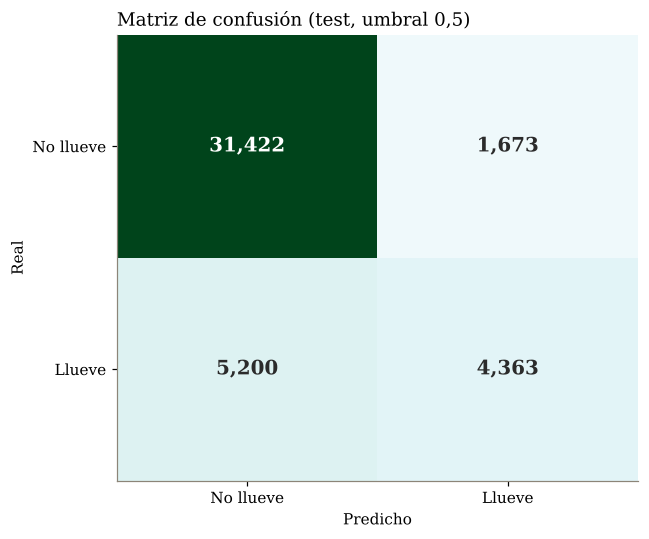

Verdaderos negativos (TN): 31,422
Falsos positivos     (FP): 1,673
Falsos negativos     (FN): 5,200
Verdaderos positivos (TP): 4,363


In [14]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
vmax = cm.max()
ax.imshow(cm, cmap='BuGn', aspect='auto', vmin=0, vmax=vmax)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=13, fontweight='bold',
            color='white' if v / vmax > 0.5 else INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(['No llueve', 'Llueve'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['No llueve', 'Llueve'])
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión (test, umbral 0,5)')
ax.grid(False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_confusion.png', bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos (TN): {tn:,}")
print(f"Falsos positivos     (FP): {fp:,}")
print(f"Falsos negativos     (FN): {fn:,}")
print(f"Verdaderos positivos (TP): {tp:,}")

## 3.2 Métricas de desempeño

In [15]:
metricas = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
}
for k, v in metricas.items():
    print(f"{k:10s}: {v:.4f}")
print(f"\nAccuracy de un modelo que siempre dice 'no llueve': {1 - y_test.mean():.4f}")

Accuracy  : 0.8389
Precision : 0.7228
Recall    : 0.4562
F1-Score  : 0.5594

Accuracy de un modelo que siempre dice 'no llueve': 0.7758


In [16]:
print(classification_report(y_test, y_pred, target_names=['No llueve', 'Llueve']))

              precision    recall  f1-score   support

   No llueve       0.86      0.95      0.90     33095
      Llueve       0.72      0.46      0.56      9563

    accuracy                           0.84     42658
   macro avg       0.79      0.70      0.73     42658
weighted avg       0.83      0.84      0.82     42658



### Interpretación de las métricas

- **Accuracy (≈ 0,84):** acierta en 84 de cada 100 días. Parece alto, pero un modelo que siempre dijera "no llueve" ya tendría cerca de 0,78, por el desbalance. O sea, la accuracy sola engaña un poco.
- **Precision (≈ 0,72):** de los días en que el modelo dice "mañana llueve", alrededor de 7 de cada 10 de verdad llueve.
- **Recall (≈ 0,46):** de los días en que realmente llovió, el modelo detecta menos de la mitad. Se le escapan muchos días de lluvia.
- **F1 (≈ 0,56):** resume precision y recall; queda bajo por culpa del recall.

**¿Qué métrica importa más?** Depende de para qué se use. Si el pronóstico sirve para, por ejemplo, planificar un evento al aire libre o una cosecha, que no avise de una lluvia que sí ocurre (falso negativo) es peor que avisar de más. En ese caso el **recall** es la métrica más importante, y hoy es el punto débil del modelo.

## 3.3 Curva ROC y AUC

### Figura 3 - Curva ROC

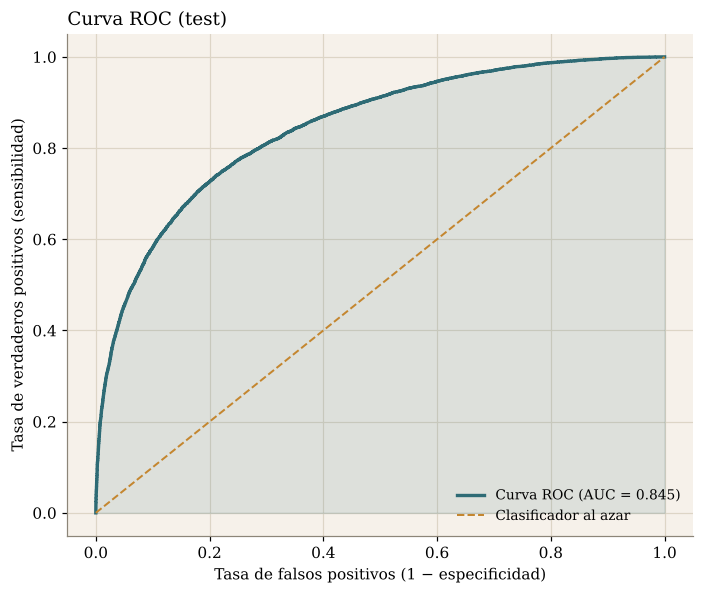

AUC = 0.8445


In [17]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.fill_between(fpr, tpr, color=TEAL, alpha=0.12)
ax.plot(fpr, tpr, color=TEAL, lw=2.2, label=f'Curva ROC (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color=OCHRE, lw=1.3, ls='--', label='Clasificador al azar')
ax.set_xlabel('Tasa de falsos positivos (1 − especificidad)')
ax.set_ylabel('Tasa de verdaderos positivos (sensibilidad)')
ax.set_title('Curva ROC (test)')
ax.legend(loc='lower right', fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(FIGURAS / 'f2_fig_roc.png', bbox_inches='tight')
plt.show()
print(f"AUC = {roc_auc:.4f}")

### Interpretación del AUC

Escala usual: 0,5 = azar · 0,6–0,7 pobre · 0,7–0,8 aceptable · **0,8–0,9 bueno** · > 0,9 excelente.

Nuestro AUC queda en el rango **bueno** (≈ 0,84). Quiere decir que si tomamos al azar un día que fue seguido de lluvia y uno que no, el modelo le da mayor probabilidad de lluvia al primero en cerca del 84 % de los casos. A diferencia de la accuracy, el AUC no depende del umbral ni se infla por el desbalance.

Que el AUC sea bueno pero el recall bajo indica que el modelo **ordena bien** los días, pero el umbral de 0,5 es muy exigente para avisar lluvia. Bajar el umbral o ponderar las clases (S3) debería subir el recall.

---
# PARTE 4: Síntesis y reflexión

## 1. Conexión con la Formativa 1
Usamos la F1 para saber qué hacer con los datos: sacamos las filas sin objetivo, marcamos como faltante la nubosidad 9, recortamos la lluvia por su cola larga y, sobre todo, dejamos fuera `Sunshine` y `Cloud3pm` por su alto porcentaje de faltantes, que fue uno de los hallazgos principales de la F1. Las correlaciones con el objetivo también vienen de ese análisis.

## 2. Conexión con la validación (bootstrap)
El bootstrap mostró que las correlaciones de las candidatas son estables (ningún intervalo toca el 0). Eso nos dio confianza en las cuatro variables elegidas. Como con tantos datos casi todo sale estable, el criterio que realmente nos ayudó a decidir fue la combinación de fuerza de la relación, porcentaje de faltantes y no repetir información.

## 3. ¿El modelo tiene buen desempeño?
Sí, con matices. El AUC (≈ 0,84) es bueno y muestra que el modelo distingue los días que van a tener lluvia. Pero con umbral 0,5 detecta solo cerca del 46 % de los días con lluvia, lo que es poco si el objetivo es avisar a tiempo. La accuracy (≈ 0,84) se ve bien, pero está apenas unos 6 puntos sobre la de un modelo que siempre dice "no llueve".

## 4. Mejoras para la Sumativa 3
- [x] **Probar otras variables:** incluir `Sunshine` y `Cloud3pm`, que son de las más fuertes, y también la ciudad o la estación del año.
- [x] **Otra estrategia de imputación:** imputación por regresión para `Sunshine` y `Cloud3pm`, comparada con eliminar casos y con la mediana.
- [x] **Ajustar varios modelos:** tres modelos (por dominio, stepwise con AIC/BIC y uno reducido) y compararlos por AUC.
- [x] **Bootstrap de los coeficientes:** intervalos de confianza para los odds ratios.
- [x] **Mejorar el recall:** usar `class_weight='balanced'` o probar otro umbral.

## Resumen final
Esta formativa nos sirvió para hacer el flujo completo de un modelo de clasificación con nuestro dataset: preparar los datos, elegir variables con fundamento, ajustar una regresión logística, interpretar los odds ratios, revisar el VIF y evaluar con matriz de confusión, métricas y curva ROC. Lo que más aprendimos es que con clases desbalanceadas la accuracy no basta y hay que mirar el recall y el AUC. También quedó claro que nuestro mayor problema son los faltantes de `Sunshine` y `Cloud3pm`, que vamos a abordar en la S3.

---
## Checklist de entrega
- [x] El notebook corre sin errores de principio a fin
- [x] Documentamos los hallazgos previos (F1 y bootstrap)
- [x] Justificamos la selección de variables
- [x] Ajustamos el modelo logístico e interpretamos los odds ratios
- [x] Calculamos el VIF
- [x] Matriz de confusión, accuracy, precision, recall, F1
- [x] Curva ROC y AUC
- [x] Respondimos la reflexión
- [x] Semilla fija (SEED = 42)